In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [2]:
df = pd.read_csv("superstore_sales.csv")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [3]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()

Dataset Shape: (10800, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   obj

In [4]:
missing_values = df.isnull().sum()
print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64


In [5]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 504


In [6]:
df = df.drop_duplicates()
print("Shape After Removing Duplicates:", df.shape)

Shape After Removing Duplicates: (10296, 21)


In [7]:
df = df.dropna(subset=["Order ID"])
print("Shape After Removing Incomplete Orders:", df.shape)

Shape After Removing Incomplete Orders: (10296, 21)


In [8]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)
df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], errors="coerce"
)
print(df[["Order Date", "Ship Date"]].dtypes)

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [9]:
numeric_columns = [
    "Sales",
    "Quantity",
    "Discount",
    "Profit",
    "Postal Code"
]
for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column], errors="coerce"
    )
print("Data Types Updated Successfully!")
df.info()

Data Types Updated Successfully!
<class 'pandas.core.frame.DataFrame'>
Index: 10296 entries, 0 to 10798
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         10296 non-null  object        
 1   Order ID       10296 non-null  object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9983 non-null   float64       
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object     

In [10]:
missing_profile = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})
missing_profile

,Missing Count,Missing Percentage
Row ID,0,0.00
Order ID,0,0.00
Order Date,302,2.93
Ship Date,302,2.93
Ship Mode,302,2.93
Customer ID,302,2.93
Customer Name,302,2.93
Segment,302,2.93
Country,302,2.93
City,302,2.93


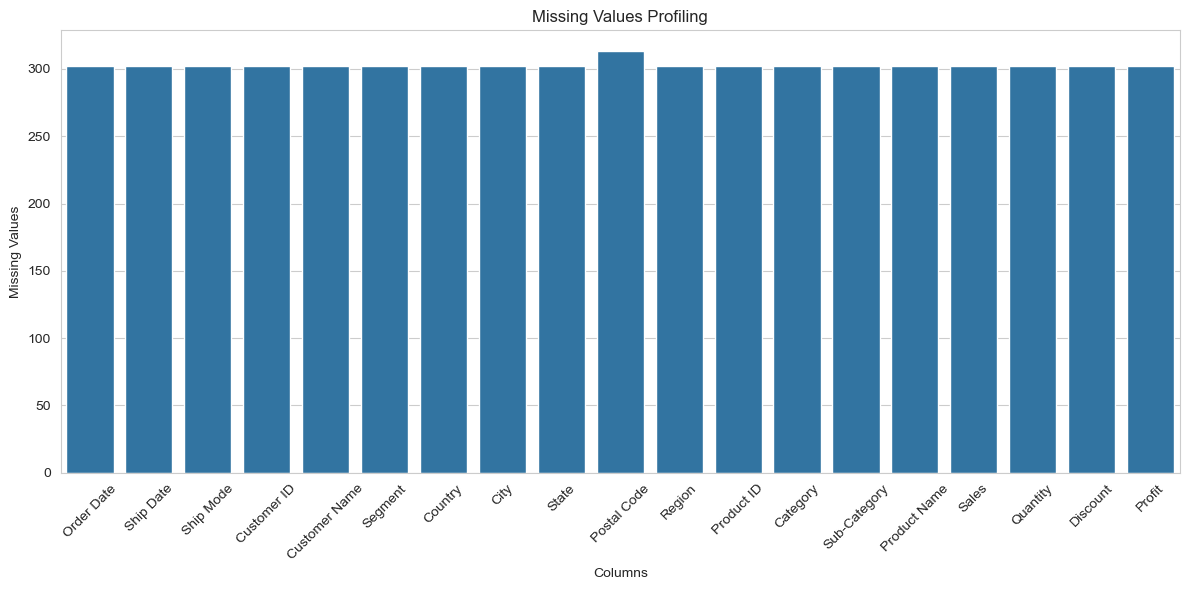

In [11]:
missing_data = missing_profile[
    missing_profile["Missing Count"] > 0
]
plt.figure(figsize=(12, 6))
sns.barplot(
    x=missing_data.index,
    y=missing_data["Missing Count"]
)
plt.title("Missing Values Profiling")
plt.xlabel("Columns")
plt.ylabel("Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Year-Month"] = df["Order Date"].dt.to_period("M")
df[["Order Date", "Year", "Month", "Year-Month"]].head()

,Order Date,Year,Month,Year-Month
0,2017-11-08,2017.0,11.0,2017-11
1,2017-11-08,2017.0,11.0,2017-11
2,2017-06-12,2017.0,6.0,2017-06
3,2016-10-11,2016.0,10.0,2016-10
4,2016-10-11,2016.0,10.0,2016-10


In [13]:
segment_analysis = df.groupby("Segment").agg(
    Total_Orders=("Order ID", "nunique"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
)
segment_analysis

,Total_Orders,Total_Sales,Total_Profit,Total_Quantity
Segment,,,,
Consumer,2586,1.161401e+06,134119.2092,19521.0
Corporate,1514,7.061464e+05,91979.1340,11608.0
Home Office,909,4.296531e+05,60298.6785,6744.0


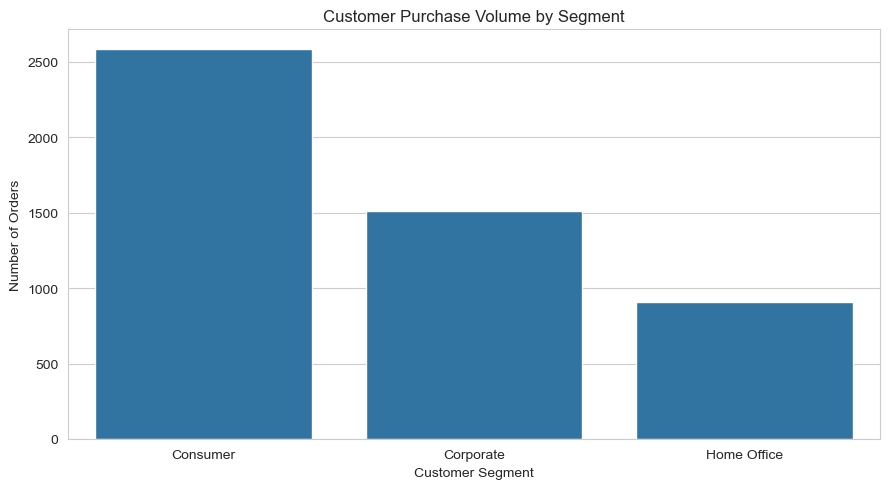

In [14]:
plt.figure(figsize=(9, 5))
sns.barplot(
    x=segment_analysis.index,
    y=segment_analysis["Total_Orders"]
)
plt.title("Customer Purchase Volume by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

In [15]:
customer_analysis = df.groupby("Customer Name").agg(
    Total_Orders=("Order ID", "nunique"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)
top_customers = customer_analysis.sort_values(
    by="Total_Sales",
    ascending=False
).head(10)
top_customers

,Total_Orders,Total_Sales,Total_Profit
Customer Name,,,
Sean Miller,5,25043.050,-1980.7393
Tamara Chand,5,19052.218,8981.3239
Raymond Buch,6,15117.339,6976.0959
Tom Ashbrook,4,14595.620,4703.7883
Adrian Barton,10,14473.571,5444.8055
Ken Lonsdale,12,14175.229,806.8550
Sanjit Chand,9,14142.334,5757.4119
Hunter Lopez,6,12873.298,5622.4292
Sanjit Engle,11,12209.438,2650.6769


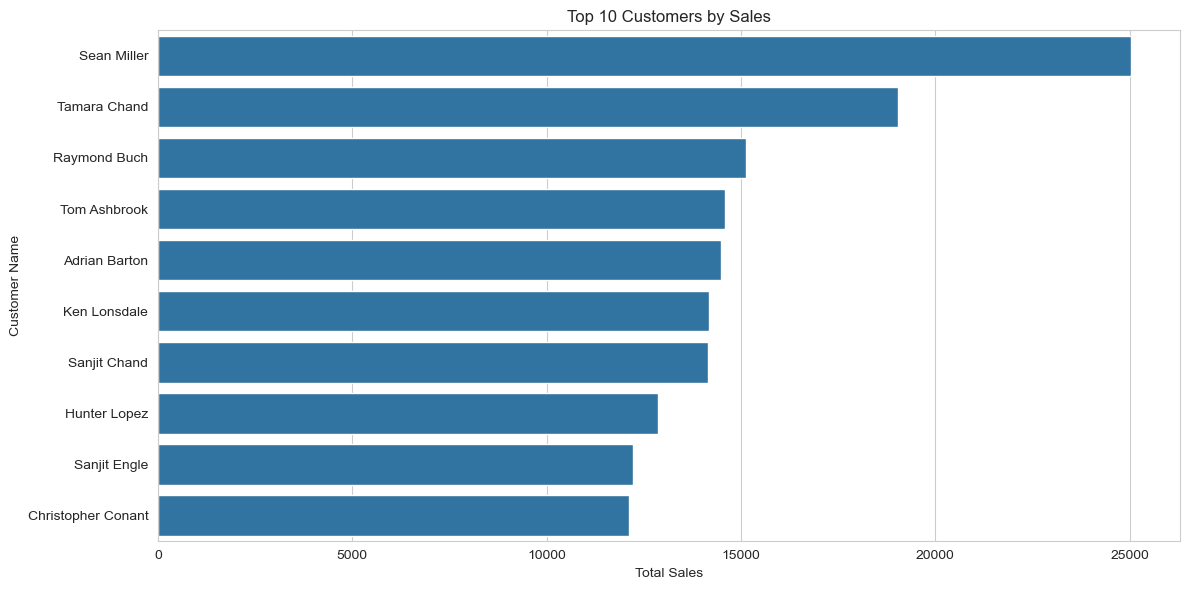

In [16]:
plt.figure(figsize=(12, 6))
sns.barplot(
    x=top_customers["Total_Sales"],
    y=top_customers.index
)
plt.title("Top 10 Customers by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer Name")
plt.tight_layout()
plt.show()

In [17]:
monthly_sales = df.groupby("Year-Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
)
monthly_sales.head()

,Total_Sales,Total_Profit,Total_Orders
Year-Month,,,
2015-01,14236.895,2450.1907,32
2015-02,4519.892,862.3084,28
2015-03,55691.009,498.7299,71
2015-04,28295.345,3488.8352,66
2015-05,23648.287,2738.7096,69


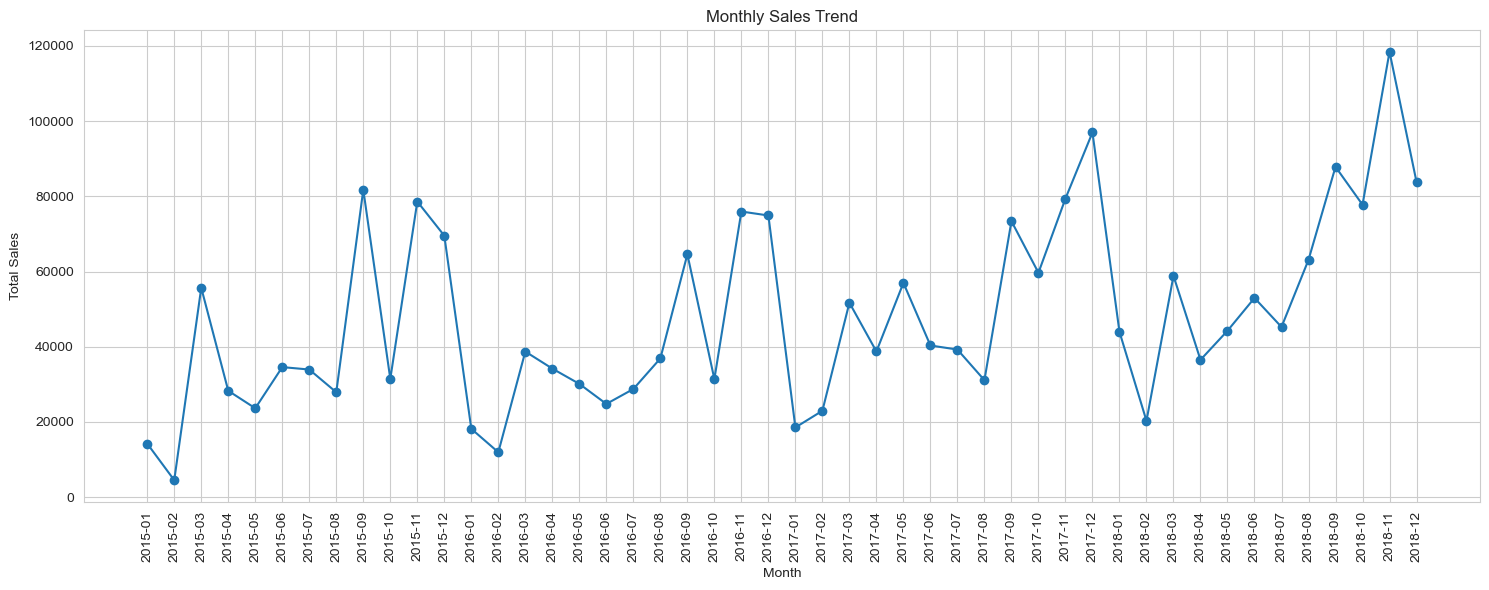

In [18]:
plt.figure(figsize=(15, 6))
plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales["Total_Sales"],
    marker="o"
)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

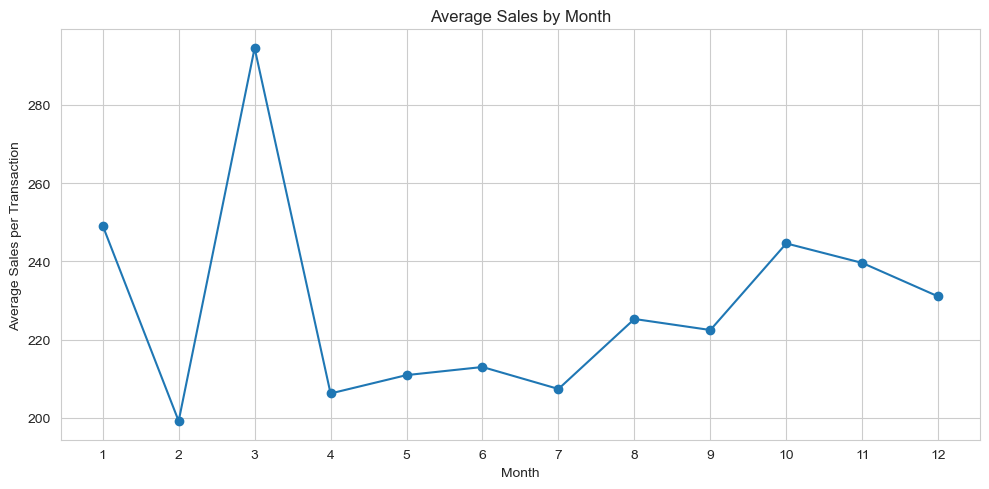

In [19]:
average_monthly_sales = df.groupby("Month")["Sales"].mean()
plt.figure(figsize=(10, 5))
plt.plot(
    average_monthly_sales.index,
    average_monthly_sales.values,
    marker="o"
)
plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Sales per Transaction")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

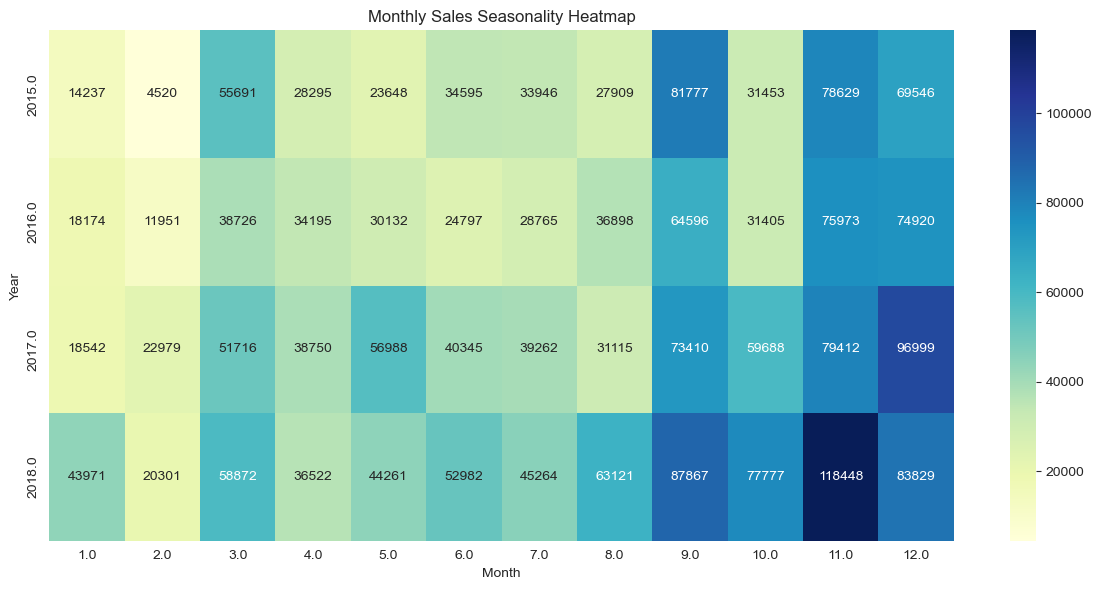

In [20]:
sales_pivot = df.pivot_table(
    values="Sales",
    index="Year",
    columns="Month",
    aggfunc="sum"
)
plt.figure(figsize=(12, 6))
sns.heatmap(
    sales_pivot,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)
plt.title("Monthly Sales Seasonality Heatmap")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

In [21]:
category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
)
category_analysis

,Total_Sales,Total_Profit,Total_Quantity
Category,,,
Furniture,741999.7953,18451.2728,8028.0
Office Supplies,719047.0320,122490.8008,22906.0
Technology,836154.0330,145454.9481,6939.0


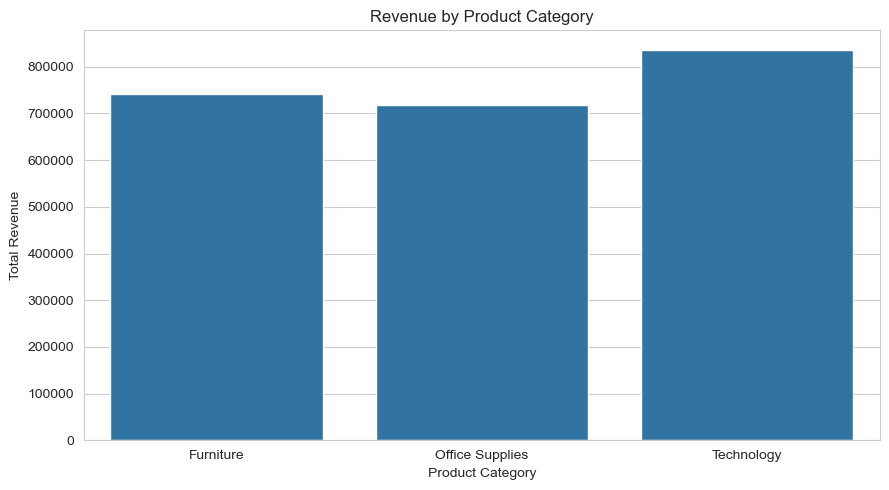

In [22]:
plt.figure(figsize=(9, 5))
sns.barplot(
    x=category_analysis.index,
    y=category_analysis["Total_Sales"]
)
plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

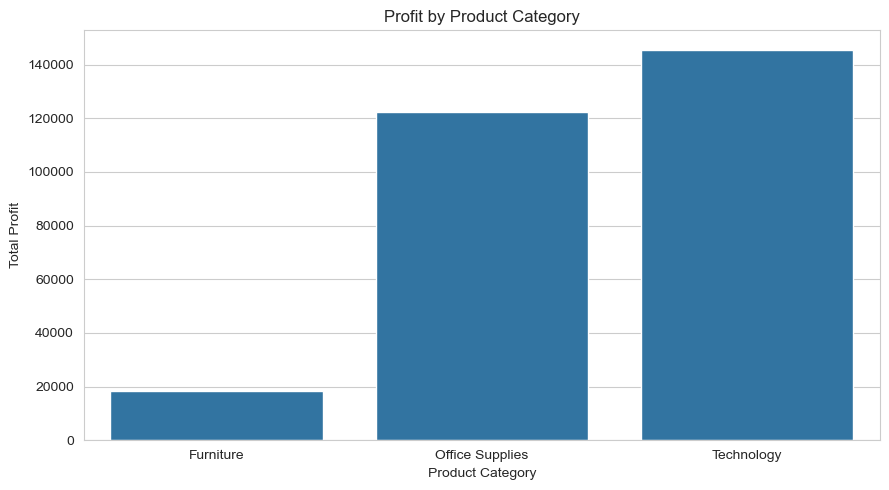

In [23]:
plt.figure(figsize=(9, 5))
sns.barplot(
    x=category_analysis.index,
    y=category_analysis["Total_Profit"]
)
plt.title("Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")
plt.tight_layout()
plt.show()

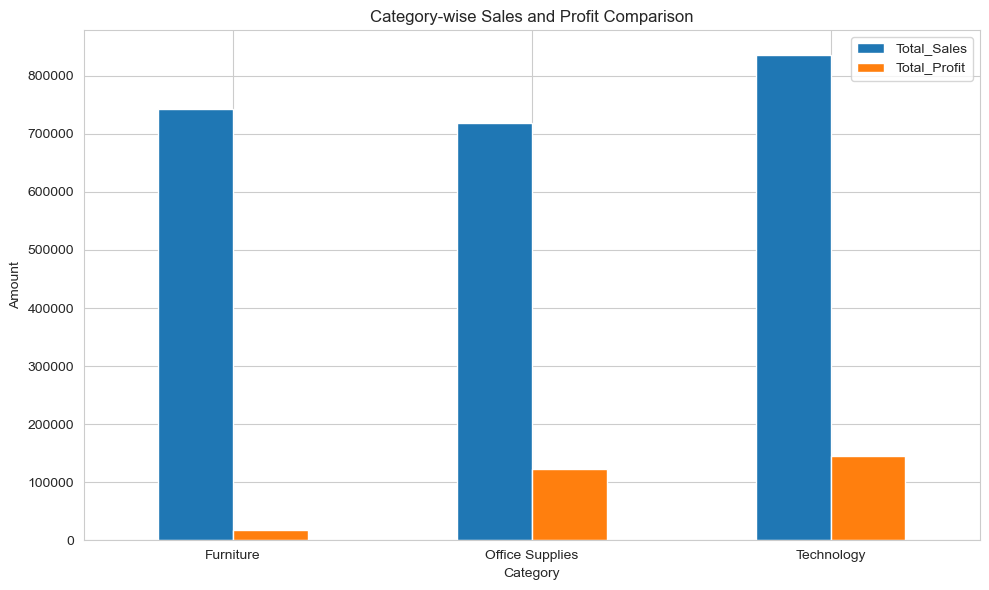

In [24]:
category_analysis[
    ["Total_Sales", "Total_Profit"]
].plot(
    kind="bar",
    figsize=(10, 6)
)
plt.title("Category-wise Sales and Profit Comparison")
plt.xlabel("Category")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

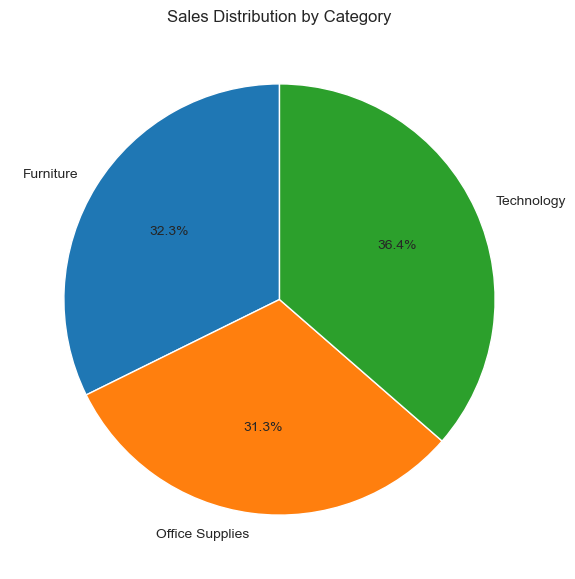

In [25]:
plt.figure(figsize=(7, 7))
plt.pie(
    category_analysis["Total_Sales"],
    labels=category_analysis.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Sales Distribution by Category")
plt.show()

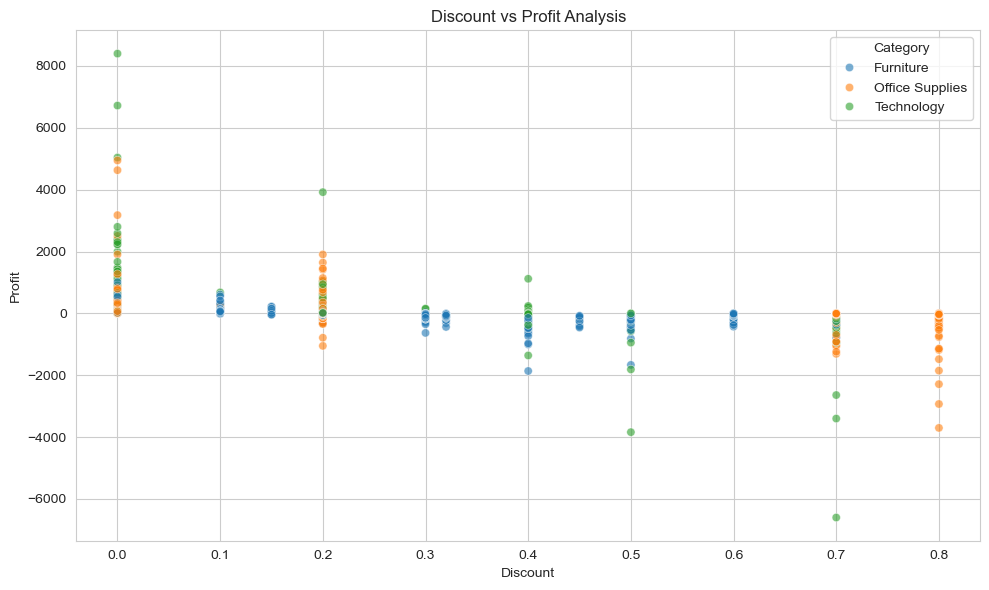

In [26]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    hue="Category",
    alpha=0.6
)
plt.title("Discount vs Profit Analysis")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

In [27]:
correlation = df["Discount"].corr(df["Profit"])
print("Discount-Profit Correlation:", round(correlation, 3))

Discount-Profit Correlation: -0.219


In [28]:
discount_analysis = df.groupby("Discount").agg(
    Average_Profit=("Profit", "mean"),
    Total_Sales=("Sales", "sum"),
    Total_Quantity=("Quantity", "sum")
)
discount_analysis

,Average_Profit,Total_Sales,Total_Quantity
Discount,,,
0.00,66.900292,1.087908e+06,18267.0
0.10,96.055074,5.436935e+04,373.0
0.15,27.288298,2.755852e+04,198.0
0.20,24.702572,7.645944e+05,13660.0
0.30,-45.679636,1.032267e+05,849.0
0.32,-88.560656,1.449346e+04,105.0
0.40,-111.927429,1.164178e+05,786.0
0.45,-226.646464,5.484974e+03,45.0
0.50,-310.703456,5.891854e+04,241.0


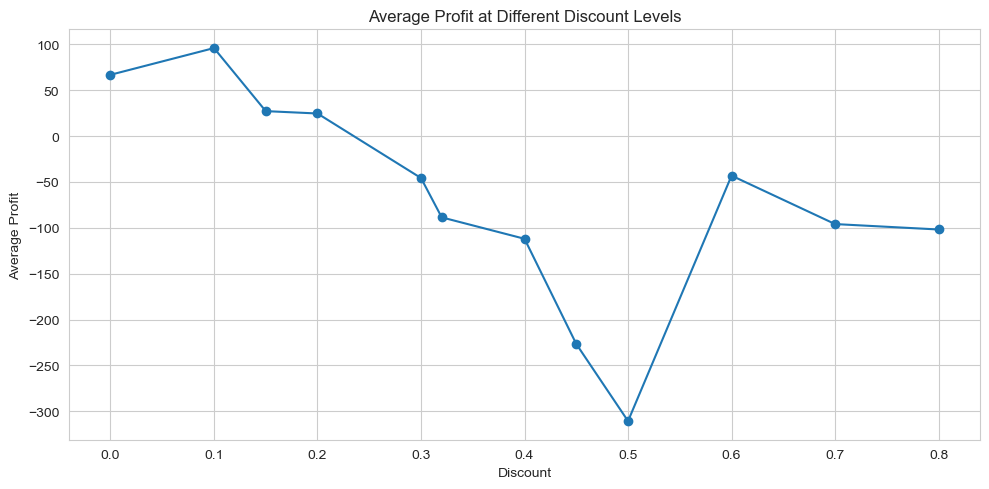

In [29]:
plt.figure(figsize=(10, 5))
plt.plot(
    discount_analysis.index,
    discount_analysis["Average_Profit"],
    marker="o"
)
plt.title("Average Profit at Different Discount Levels")
plt.xlabel("Discount")
plt.ylabel("Average Profit")
plt.grid(True)
plt.tight_layout()
plt.show()

In [30]:
region_analysis = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
)

region_analysis

,Total_Sales,Total_Profit,Total_Orders
Region,,,
Central,501239.8908,39706.3625,1175
East,678781.2400,91522.7800,1401
South,391721.9050,46749.4303,822
West,725457.8245,108418.4489,1611


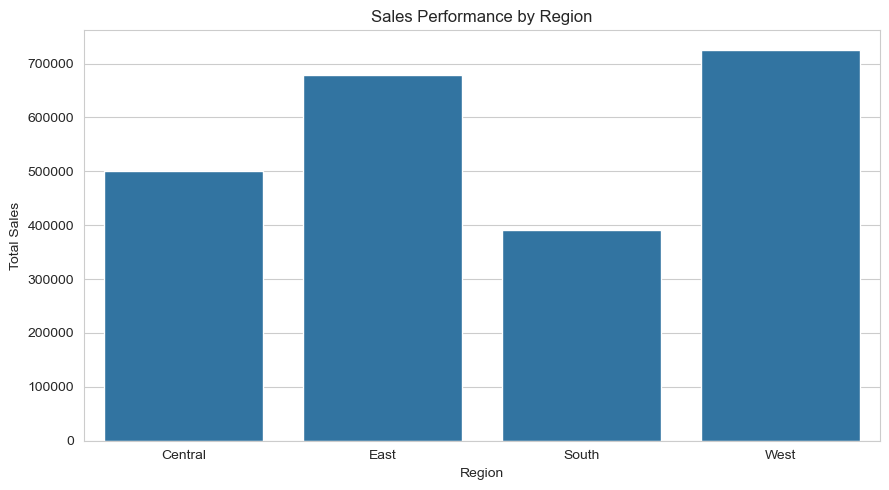

In [31]:
plt.figure(figsize=(9, 5))
sns.barplot(
    x=region_analysis.index,
    y=region_analysis["Total_Sales"]
)
plt.title("Sales Performance by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [32]:
subcategory_sales = df.groupby("Sub-Category")["Sales"].sum()
top_10 = subcategory_sales.sort_values(
    ascending=False
).head(10)
top_10

Sub-Category
Phones         330007.0540
Chairs         328449.1030
Storage        223843.6080
Tables         206965.5320
Binders        203412.7330
Machines       189238.6310
Accessories    167380.3180
Copiers        149528.0300
Bookcases      114879.9963
Appliances     107532.1610
Name: Sales, dtype: float64

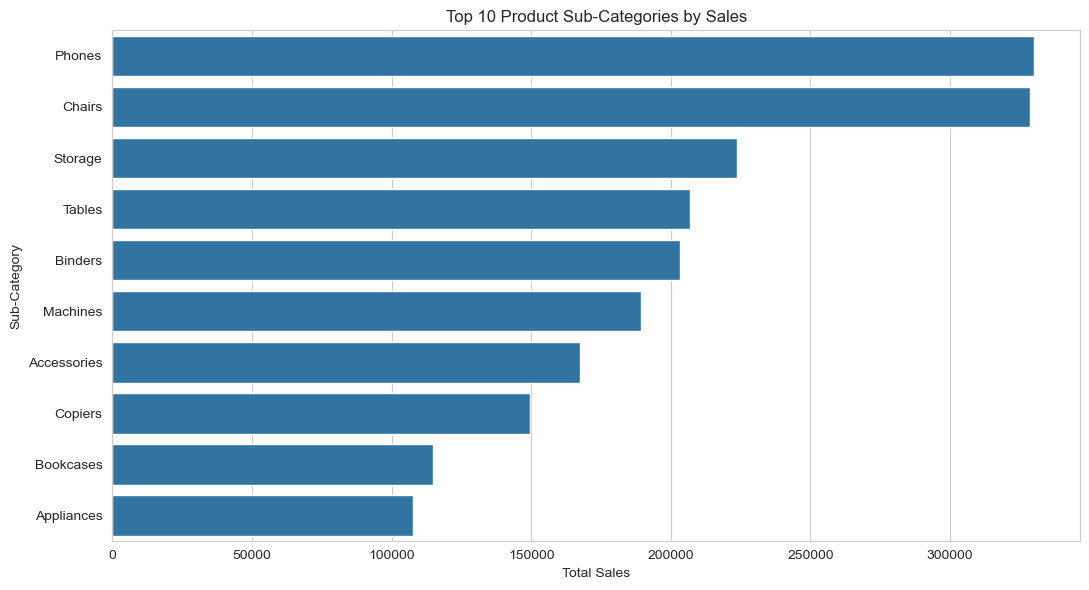

In [33]:
plt.figure(figsize=(11, 6))
sns.barplot(
    x=top_10.values,
    y=top_10.index
)
plt.title("Top 10 Product Sub-Categories by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()

In [34]:
best_category = category_analysis["Total_Sales"].idxmax()
best_category_sales = category_analysis["Total_Sales"].max()
best_profit_category = category_analysis["Total_Profit"].idxmax()
best_category_profit = category_analysis["Total_Profit"].max()
best_segment = segment_analysis["Total_Orders"].idxmax()
best_segment_orders = segment_analysis["Total_Orders"].max()
best_region = region_analysis["Total_Sales"].idxmax()
best_region_sales = region_analysis["Total_Sales"].max()
best_month = monthly_sales["Total_Sales"].idxmax()
best_month_sales = monthly_sales["Total_Sales"].max()
discount_correlation = df["Discount"].corr(df["Profit"])
print("EXECUTIVE BUSINESS TAKEAWAYS\n")
print(
    f"1. {best_category} is the highest revenue category "
    f"with sales of ${best_category_sales:,.2f}."
)
print(
    f"2. {best_profit_category} generates the highest profit "
    f"of ${best_category_profit:,.2f}."
)
print(
    f"3. {best_segment} has the highest purchase volume "
    f"with {best_segment_orders} unique orders."
)
print(
    f"4. {best_region} is the leading sales region "
    f"with revenue of ${best_region_sales:,.2f}."
)
print(
    f"5. The highest sales month is {best_month} "
    f"with sales of ${best_month_sales:,.2f}."
)
print(
    f"6. Discount and profit correlation is "
    f"{discount_correlation:.3f}."
)

EXECUTIVE BUSINESS TAKEAWAYS

1. Technology is the highest revenue category with sales of $836,154.03.
2. Technology generates the highest profit of $145,454.95.
3. Consumer has the highest purchase volume with 2586 unique orders.
4. West is the leading sales region with revenue of $725,457.82.
5. The highest sales month is 2018-11 with sales of $118,447.82.
6. Discount and profit correlation is -0.219.


In [35]:
print("FINAL DATASET SUMMARY")
print("-----------------------------")
print("Total Records:", len(df))
print("Total Columns:", len(df.columns))
print("Total Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))
print("Total Quantity:", df["Quantity"].sum())
print("Unique Customers:", df["Customer ID"].nunique())
print("Unique Orders:", df["Order ID"].nunique())
print("Duplicate Rows:", df.duplicated().sum())
print("Missing Values:", df.isnull().sum().sum())

FINAL DATASET SUMMARY
-----------------------------
Total Records: 10296
Total Columns: 24
Total Sales: 2297200.86
Total Profit: 286397.02
Total Quantity: 37873.0
Unique Customers: 793
Unique Orders: 5015
Duplicate Rows: 0
Missing Values: 6655


# Conclusion

Exploratory Data Analysis (EDA) was performed on the Superstore Retail Sales dataset using Python.

The dataset was cleaned and analyzed using Pandas, NumPy, Matplotlib, and Seaborn. Missing values and duplicate records were examined, and date columns were converted into appropriate formats.

Customer purchase volume, monthly sales seasonality, category-wise revenue, regional sales performance, and discount sensitivity were analyzed through statistical summaries and visualizations.

The analysis helped identify important business patterns, customer purchasing behavior, profitable product categories, and the relationship between discounts and profit.

Finally, executive business takeaways were generated to support better business decisions and improve overall sales performance.